<a href="https://colab.research.google.com/github/evanmccarthy216/h96ahNh2WKWrsjlT/blob/main/customer_happinessl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!gdown 1KWE3J0uU_sFIJnZ74Id3FDBcejELI7FD -O survey.csv

import pandas as pd
df = pd.read_csv("survey.csv")
df.head()

Downloading...
From: https://drive.google.com/uc?id=1KWE3J0uU_sFIJnZ74Id3FDBcejELI7FD
To: /content/survey.csv
100% 1.91k/1.91k [00:00<00:00, 3.66MB/s]


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


Y = target attribute (Y) with values indicating 0 (unhappy) and 1 (happy) customers

X1 = my order was delivered on time

X2 = contents of my order was as I expected

X3 = I ordered everything I wanted to order

X4 = I paid a good price for my order

X5 = I am satisfied with my courier

X6 = the app makes ordering easy for me

In [2]:
print(df.shape)
print(df.isnull().sum())
print(df.dtypes)

(126, 7)
Y     0
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
dtype: int64
Y     int64
X1    int64
X2    int64
X3    int64
X4    int64
X5    int64
X6    int64
dtype: object


The dataset has 126 survey responses with no missing values. All features are integer ratings from 1 to 5, and Y is a binary label (0/1).


In [3]:
print(df["Y"].value_counts())
print(df["Y"].value_counts(normalize=True))

Y
1    69
0    57
Name: count, dtype: int64
Y
1    0.547619
0    0.452381
Name: proportion, dtype: float64


Happy customers = 69  
54.7% are happy

Unhappy customers = 57   
45.2% are unhappy


In [5]:
# summary stats
df.describe()

,Y,X1,X2,X3,X4,X5,X6
count,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000
mean,0.547619,4.333333,2.531746,3.309524,3.746032,3.650794,4.253968
std,0.499714,0.800000,1.114892,1.023440,0.875776,1.147641,0.809311
min,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,4.000000,2.000000,3.000000,3.000000,3.000000,4.000000
50%,1.000000,5.000000,3.000000,3.000000,4.000000,4.000000,4.000000
75%,1.000000,5.000000,3.000000,4.000000,4.000000,4.000000,5.000000
max,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [6]:
for col in ["X1", "X2", "X3", "X4", "X5", "X6"]:
    print(f"\n{col}")
    print(df.groupby(col)["Y"].agg(["mean", "count"]).round(2))


X1
    mean  count
X1             
1   0.00      1
3   0.40     20
4   0.40     40
5   0.69     65

X2
    mean  count
X2             
1   0.52     27
2   0.62     34
3   0.55     42
4   0.41     17
5   0.67      6

X3
    mean  count
X3             
1   0.43      7
2   0.50     14
3   0.47     55
4   0.67     33
5   0.65     17

X4
    mean  count
X4             
1   1.00      2
2   0.20      5
3   0.51     41
4   0.57     53
5   0.60     25

X5
    mean  count
X5             
1   0.29      7
2   0.44     16
3   0.45     22
4   0.56     50
5   0.71     31

X6
    mean  count
X6             
1   1.00      1
2   0.00      1
3   0.30     20
4   0.57     47
5   0.61     57


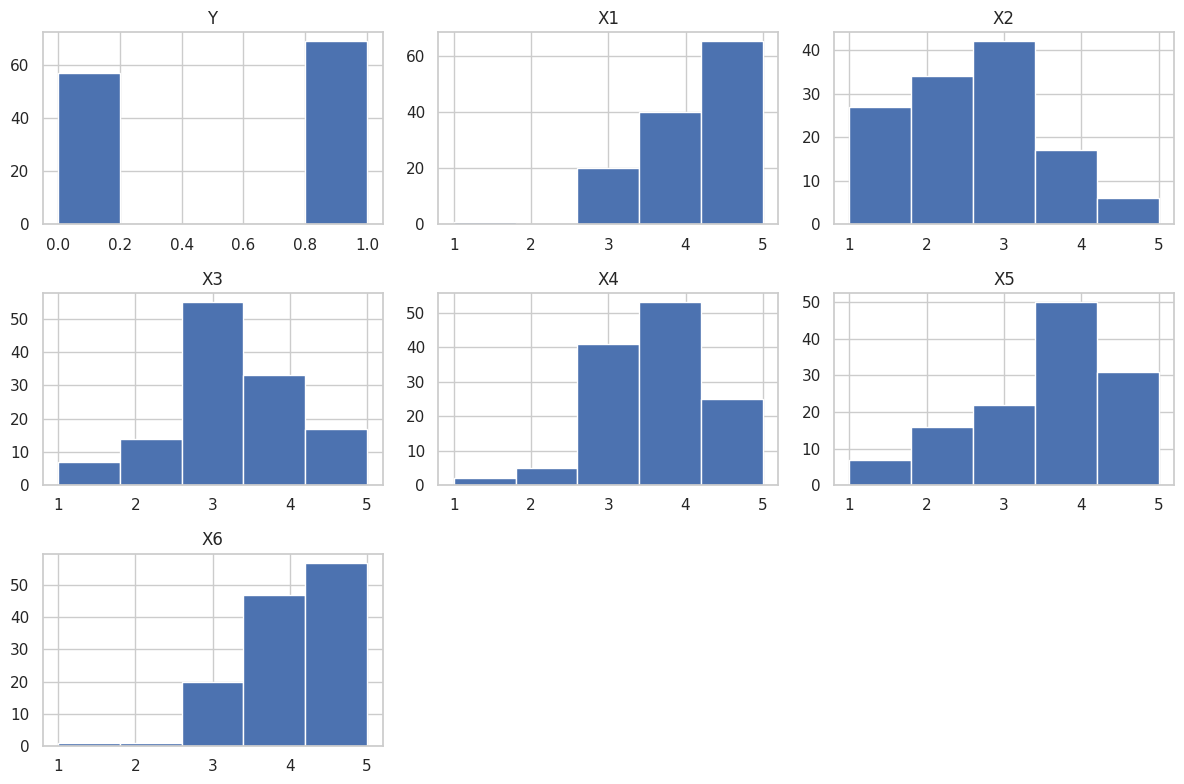

In [9]:
sns.set(style="whitegrid")
#affter leanring basic stats of this data set. we wana plot.
#we will create a hist for every columns to show how survey scores are desributed.
df.hist(bins=5, figsize=(12,8))
plt.tight_layout() #fixes spaces so that plots dont overlap
plt.show()

**Strong signal**

X1 (on-time delivery) is the clearest. Customers who answered 5 were 69% happy, while those who answered 3 or 4 were only 40% happy. The jump is at the very top: “on time” isn’t enough, it has to be a 5.
X5 (courier satisfaction) climbs steadily: 29% → 44% → 45% → 56% → 71%. That clean upward trend is exactly what a useful feature looks like.

**Moderate signal**

X3 (ordered everything I wanted) splits into two groups. Answers 1–3 sit around 45–50% happy, and answers 4–5 sit around 65%.
X6 (app is easy) goes from 30% happy at 3 to about 60% at 4–5. Almost nobody rated it below 3, though.

**Weak or no signal**

X4 (good price) is basically flat from 51% to 60% across the answers most people gave.
X2 (contents as expected) has no pattern at all. It bounces up and down (52, 62, 55, 41, 67). This is your first candidate for a question to drop from the survey.

Ignore the tiny groups. Rows like X4 = 1 (100% happy) or X6 = 2 (0% happy) are based on 1 or 2 customers. That’s noise, not a finding.

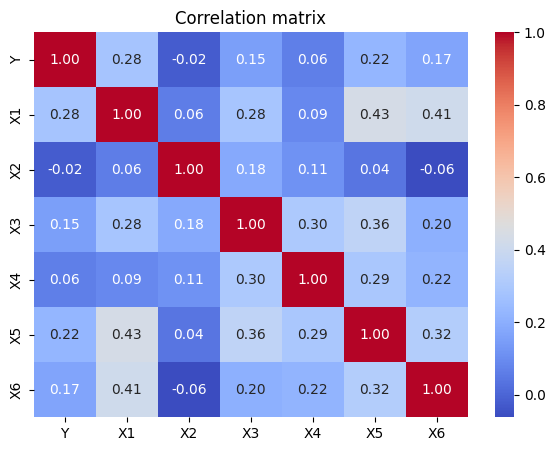

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

The biggest overlaps are X1–X5 (0.43) and X1–X6 (0.41). Customers who rate delivery timing highly tend to rate the courier and the app highly too, so these three may partly capture one overall “the service worked” feeling.

Nothing is above 0.5, so no two questions are truly redundant. Each adds at least some information of its own.

X2 is uncorrelated with everything, including Y. It measures something separate from the other questions, and that something doesn’t relate to happiness. That makes it the clearest candidate to drop.